In [68]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Ellipse
from matplotlib.backends.backend_pdf import PdfPages 
from shapely import wkt

In [69]:
url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" 
url_county = "cb_2024_us_county_500k.zip"
url_state = "cb_2024_us_state_500k.zip"

<Axes: >

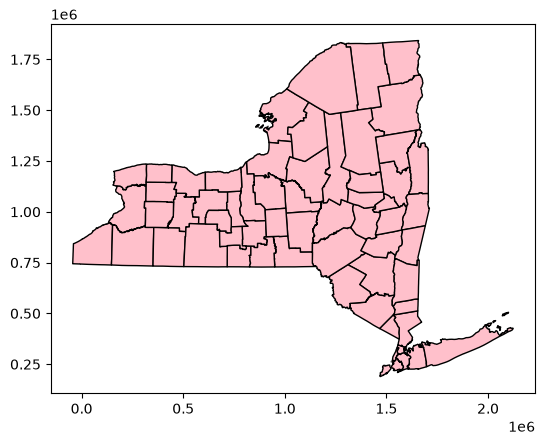

In [70]:
counties = gpd.read_file(url_0 + url_county)
ny_counties = counties.loc[counties['STATEFP']== '36'].to_crs(2261)
ny_counties.plot(edgecolor='black', facecolor='pink')

In [71]:
parks = gpd.read_file("State_Park_Facility_Points_20261028.csv")
parks

,Name,Category,Region,County,Golf,Camp,Playground,Nature Center,Beach,Facility URL,Golf URL,Nature Center URL,Longitude,Latitude,Location,Georeference
0,Amherst,State Park,1,Erie,N,N,N,,N,,,,-78.74808818,42.97100087,"(42.97100087, -78.74808818)",POINT (-78.74808818 42.97100087)
1,Genesee River,Other,3,Monroe,N,N,N,,N,,,,-77.61431271,43.23058471,"(43.23058471, -77.61431271)",POINT (-77.61431271 43.23058471)
2,Galop Island,State Park,10,St. Lawrence,N,N,N,,N,,,,-75.39276378,44.76843672,"(44.76843672, -75.39276378)",POINT (-75.39276378 44.76843672)
3,Blauvelt,State Park,8,Rockland,N,N,N,,N,https://parks.ny.gov/parks/49/details.aspx,,,-73.93737308,41.07424137,"(41.07424137, -73.93737308)",POINT (-73.93737308 41.07424137)
4,Wonder Lake,State Park,7,Putnam,N,N,N,,N,https://parks.ny.gov/parks/190/details.aspx,,,-73.64658631,41.49190316,"(41.49190316, -73.64658631)",POINT (-73.64658631 41.49190316)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,State Park at the Fair,State Park,5,Onondaga,N,N,N,,N,https://parks.ny.gov/parks/82/details.aspx,,,-76.21696591,43.07110463,"(43.07110463, -76.21696591)",POINT (-76.21696591 43.07110463)
250,Nyack Beach,State Park,8,Rockland,N,N,N,,N,https://parks.ny.gov/parks/156/details.aspx,,,-73.90865449,41.1271277,"(41.1271277, -73.90865449)",POINT (-73.90865449 41.1271277)
251,Camp Hero,State Park,9,Suffolk,N,N,N,,N,https://parks.ny.gov/parks/97/details.aspx,,,-71.8777873,41.06177195,"(41.06177195, -71.8777873)",POINT (-71.8777873 41.06177195)
252,Mary Island,State Park,10,Jefferson,N,Y,N,,N,https://parks.ny.gov/parks/40/details.aspx,,,-75.92157812,44.3655711,"(44.3655711, -75.92157812)",POINT (-75.92157812 44.3655711)


In [72]:
ny_counties

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry
40,36,005,00974101,0500000US36005,36005,Bronx,Bronx County,NY,New York,06,109235672,39353304,"MULTIPOLYGON (((1597756.99 325604.348, 1598281..."
42,36,119,00974157,0500000US36119,36119,Westchester,Westchester County,NY,New York,06,1115811940,179391718,"MULTIPOLYGON (((1597474.278 334807.616, 159769..."
43,36,053,00974125,0500000US36053,36053,Madison,Madison County,NY,New York,06,1696054034,16691322,"POLYGON ((977803.52 1161116.349, 978122.783 11..."
46,36,029,00974113,0500000US36029,36029,Erie,Erie County,NY,New York,06,2700743425,476876396,"POLYGON ((132350.925 946665.664, 133539.401 95..."
48,36,091,00974143,0500000US36091,36091,Saratoga,Saratoga County,NY,New York,06,2097812305,87488004,"POLYGON ((1464528.712 1237845.771, 1500185.037..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2778,36,019,00974108,0500000US36019,36019,Clinton,Clinton County,NY,New York,06,2687763025,206581998,"POLYGON ((1481395.549 1830998.35, 1499212.179 ..."
2785,36,123,00974159,0500000US36123,36123,Yates,Yates County,NY,New York,06,875777224,97488350,"POLYGON ((609418.46 973008.474, 612027.823 973..."
2898,36,027,00974112,0500000US36027,36027,Dutchess,Dutchess County,NY,New York,06,2060598611,76906718,"POLYGON ((1528328.126 542340.215, 1528569.57 5..."
2964,36,035,00974116,0500000US36035,36035,Fulton,Fulton County,NY,New York,06,1283234687,96916403,"POLYGON ((1303512.167 1128271.442, 1303636.78 ..."


In [73]:
parks['Georeference'] = parks['Georeference'].apply(wkt.loads)

In [74]:
park_pts = gpd.GeoDataFrame(parks, geometry=parks['Georeference']).set_crs(2261, allow_override=True)

In [75]:
parks_fixed = gpd.GeoDataFrame(
    park_pts.drop(columns="geometry", errors="ignore"),
    geometry=gpd.points_from_xy(
        park_pts["Longitude"],
        park_pts["Latitude"]
    ),
    crs="EPSG:4326"
)

parks_fixed = parks_fixed.to_crs(ny_counties.crs)

print(parks_fixed.total_bounds)
print(parks_fixed.geometry.head())

[   5939.34618484  205657.45565816 2118004.00821398 1827267.14018126]
0      POINT (240842.03 1089968.676)
1     POINT (545448.169 1178807.818)
2    POINT (1129407.714 1739951.734)
3      POINT (1549752.22 402415.518)
4      POINT (1624785.602 557183.24)
Name: geometry, dtype: geometry


<Axes: >

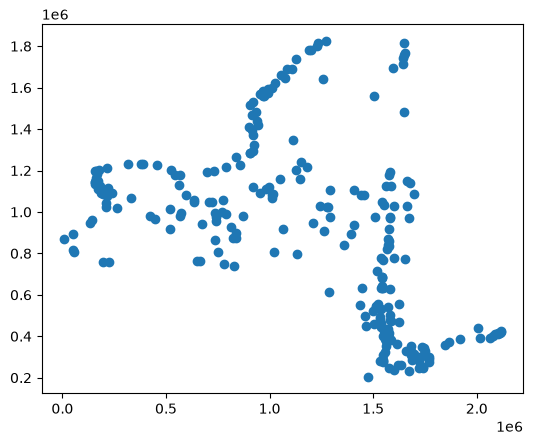

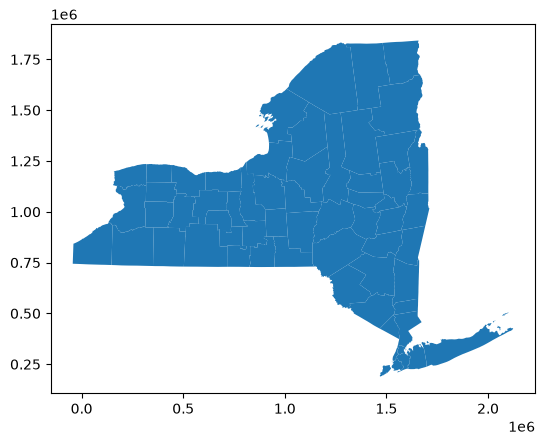

In [76]:
parks_fixed.plot()
ny_counties.plot()

In [77]:
ny_parks = gpd.sjoin(parks_fixed, ny_counties, 'inner', 'within')

In [78]:
ny_parks

,Name,Category,Region,County,Golf,Camp,Playground,Nature Center,Beach,Facility URL,...,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER
0,Amherst,State Park,1,Erie,N,N,N,,N,,...,00974113,0500000US36029,36029,Erie,Erie County,NY,New York,06,2700743425,476876396
1,Genesee River,Other,3,Monroe,N,N,N,,N,,...,00974126,0500000US36055,36055,Monroe,Monroe County,NY,New York,06,1701477037,1838269506
2,Galop Island,State Park,10,St. Lawrence,N,N,N,,N,,...,00977309,0500000US36089,36089,St. Lawrence,St. Lawrence County,NY,New York,06,6939939685,366960962
3,Blauvelt,State Park,8,Rockland,N,N,N,,N,https://parks.ny.gov/parks/49/details.aspx,...,00974142,0500000US36087,36087,Rockland,Rockland County,NY,New York,06,449840998,66919666
4,Wonder Lake,State Park,7,Putnam,N,N,N,,N,https://parks.ny.gov/parks/190/details.aspx,...,00974138,0500000US36079,36079,Putnam,Putnam County,NY,New York,06,596350119,41229629
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249,State Park at the Fair,State Park,5,Onondaga,N,N,N,,N,https://parks.ny.gov/parks/82/details.aspx,...,00974132,0500000US36067,36067,Onondaga,Onondaga County,NY,New York,06,2016027798,70512842
250,Nyack Beach,State Park,8,Rockland,N,N,N,,N,https://parks.ny.gov/parks/156/details.aspx,...,00974142,0500000US36087,36087,Rockland,Rockland County,NY,New York,06,449840998,66919666
251,Camp Hero,State Park,9,Suffolk,N,N,N,,N,https://parks.ny.gov/parks/97/details.aspx,...,00974149,0500000US36103,36103,Suffolk,Suffolk County,NY,New York,06,2359306969,3787388317
252,Mary Island,State Park,10,Jefferson,N,Y,N,,N,https://parks.ny.gov/parks/40/details.aspx,...,00974121,0500000US36045,36045,Jefferson,Jefferson County,NY,New York,06,3283924240,1524538853


In [79]:
counts = ny_parks['NAME'].value_counts('index_right')
counts

NAME
Suffolk         0.106719
Jefferson       0.071146
Niagara         0.051383
St. Lawrence    0.047431
Rockland        0.043478
Erie            0.035573
Orange          0.035573
Westchester     0.035573
Dutchess        0.027668
Seneca          0.023715
Otsego          0.023715
Nassau          0.023715
Ontario         0.023715
Oswego          0.023715
Clinton         0.023715
Columbia        0.023715
Monroe          0.019763
Oneida          0.019763
Rensselaer      0.019763
Chautauqua      0.019763
Saratoga        0.019763
Putnam          0.015810
Onondaga        0.015810
Ulster          0.015810
Tompkins        0.015810
Steuben         0.011858
New York        0.011858
Cayuga          0.011858
Madison         0.011858
Albany          0.007905
Wayne           0.007905
Montgomery      0.007905
Schenectady     0.007905
Essex           0.007905
Washington      0.007905
Queens          0.007905
Kings           0.007905
Cattaraugus     0.007905
Chemung         0.007905
Broome          0.00

In [80]:
num_counts = counts * 253
num_counts

NAME
Suffolk         27.0
Jefferson       18.0
Niagara         13.0
St. Lawrence    12.0
Rockland        11.0
Erie             9.0
Orange           9.0
Westchester      9.0
Dutchess         7.0
Seneca           6.0
Otsego           6.0
Nassau           6.0
Ontario          6.0
Oswego           6.0
Clinton          6.0
Columbia         6.0
Monroe           5.0
Oneida           5.0
Rensselaer       5.0
Chautauqua       5.0
Saratoga         5.0
Putnam           4.0
Onondaga         4.0
Ulster           4.0
Tompkins         4.0
Steuben          3.0
New York         3.0
Cayuga           3.0
Madison          3.0
Albany           2.0
Wayne            2.0
Montgomery       2.0
Schenectady      2.0
Essex            2.0
Washington       2.0
Queens           2.0
Kings            2.0
Cattaraugus      2.0
Chemung          2.0
Broome           2.0
Greene           2.0
Wyoming          2.0
Schoharie        2.0
Orleans          2.0
Herkimer         1.0
Richmond         1.0
Schuyler         1.0
Sullivan

In [81]:
num_counts.to_dict()

{'Suffolk': 27.0,
 'Jefferson': 18.0,
 'Niagara': 13.0,
 'St. Lawrence': 12.0,
 'Rockland': 11.0,
 'Erie': 9.0,
 'Orange': 9.0,
 'Westchester': 9.0,
 'Dutchess': 7.0,
 'Seneca': 6.0,
 'Otsego': 6.0,
 'Nassau': 6.0,
 'Ontario': 6.0,
 'Oswego': 6.0,
 'Clinton': 6.0,
 'Columbia': 6.0,
 'Monroe': 5.0,
 'Oneida': 5.0,
 'Rensselaer': 5.0,
 'Chautauqua': 5.0,
 'Saratoga': 5.0,
 'Putnam': 3.9999999999999996,
 'Onondaga': 3.9999999999999996,
 'Ulster': 3.9999999999999996,
 'Tompkins': 3.9999999999999996,
 'Steuben': 3.0,
 'New York': 3.0,
 'Cayuga': 3.0,
 'Madison': 3.0,
 'Albany': 1.9999999999999998,
 'Wayne': 1.9999999999999998,
 'Montgomery': 1.9999999999999998,
 'Schenectady': 1.9999999999999998,
 'Essex': 1.9999999999999998,
 'Washington': 1.9999999999999998,
 'Queens': 1.9999999999999998,
 'Kings': 1.9999999999999998,
 'Cattaraugus': 1.9999999999999998,
 'Chemung': 1.9999999999999998,
 'Broome': 1.9999999999999998,
 'Greene': 1.9999999999999998,
 'Wyoming': 1.9999999999999998,
 'Schoharie

In [82]:
num_counts // 1

NAME
Suffolk         27.0
Jefferson       18.0
Niagara         13.0
St. Lawrence    12.0
Rockland        11.0
Erie             9.0
Orange           9.0
Westchester      9.0
Dutchess         7.0
Seneca           6.0
Otsego           6.0
Nassau           6.0
Ontario          6.0
Oswego           6.0
Clinton          6.0
Columbia         6.0
Monroe           5.0
Oneida           5.0
Rensselaer       5.0
Chautauqua       5.0
Saratoga         5.0
Putnam           3.0
Onondaga         3.0
Ulster           3.0
Tompkins         3.0
Steuben          3.0
New York         3.0
Cayuga           3.0
Madison          3.0
Albany           1.0
Wayne            1.0
Montgomery       1.0
Schenectady      1.0
Essex            1.0
Washington       1.0
Queens           1.0
Kings            1.0
Cattaraugus      1.0
Chemung          1.0
Broome           1.0
Greene           1.0
Wyoming          1.0
Schoharie        1.0
Orleans          1.0
Herkimer         0.0
Richmond         0.0
Schuyler         0.0
Sullivan

In [83]:
num_counts.sum()

np.float64(253.0)

In [108]:
def county_map(county, ax):
    selected = ny_counties[ny_counties["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()
def locator_map(county, ax):
    selected = ny_counties[ny_counties["NAME"] == county]
    ny_counties.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="#7b9b90")
    ax.set_axis_off()
def county_figure(county, pdf):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    pdf.savefig(fig)
    plt.close(fig)
def county_pie(county, ax):
    selected = ny_counties[ny_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]

    ax.pie(
        [land, water],
        labels=["Land", "Water"],
        colors=["olivedrab", "steelblue"],
        autopct="%.1f%%",
        startangle=90
    )

    ax.set_title("Land and water")
def county_info(county, ax):
    selected = ny_counties[ny_counties["NAME"] == county]

    land = selected["ALAND"].iloc[0]
    water = selected["AWATER"].iloc[0]
    park_val = num_counts.get(county, 0)

    ## Using ai and https://matplotlib.org/stable/gallery/shapes_and_collections/hatch_demo.html
    # Land icon: mountains
    mountain = Polygon(
        [(0.02, 0.60), (0.09, 0.80), (0.14, 0.69),
         (0.19, 0.76), (0.25, 0.60)],
        facecolor="olivedrab",
        transform=ax.transAxes
    )
    ax.add_patch(mountain)

    # Water icon
    lake = Ellipse(
        (0.13, 0.30),
        width=0.23,
        height=0.12,
        facecolor="steelblue",
        transform=ax.transAxes
    )
    ax.add_patch(lake)

    ax.text(
        0.32, 0.80,
        f"LAND\n{land / 1_000_000:,.2f} km²\n"
        f"{land / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="olivedrab",
        va="top"
    )

    ax.text(
        0.32, 0.40,
        f"WATER\n{water / 1_000_000:,.2f} km²\n"
        f"{water / 2_589_988.110336:,.2f} square miles",
        transform=ax.transAxes,
        fontsize=14,
        color="steelblue",
        va="top"
    )

    if park_val != 1:
        ax.text(
            0.05, 0.90,
            f"{park_val} parks",
            fontsize= 14,
            color = '#0a481e',
            va= 'top'
        )
    else:
        ax.text(
            0.05, 0.90,
            f"{park_val} park",
            fontsize= 14,
            color = '#0a481e',
            va= 'top'
        )

    ax.set_axis_off()
def county_figure(county, pdf):

    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    # Coded with Ai help
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.05, 0.08, 0.25, 0.12])
    ax_pie = fig.add_axes([0.65, 0.48, 0.30, 0.30])
    ax_info = fig.add_axes([0.65, 0.12, 0.30, 0.32])


    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_pie(county, ax_pie)
    county_info(county, ax_info)

    # Page heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / County Water-Land Atlas",
        fontsize=10,
        color="olivedrab"
    )

    fig.text(
        0.05, 0.87,
        f"{county} County",
        fontsize=28,
        fontweight="bold"
    )

    # Footer
    fig.text(
        0.05, 0.03,
        "Source: U.S. Census Bureau | Areas from ALAND and AWATER",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig, dpi=50)
    plt.close(fig)

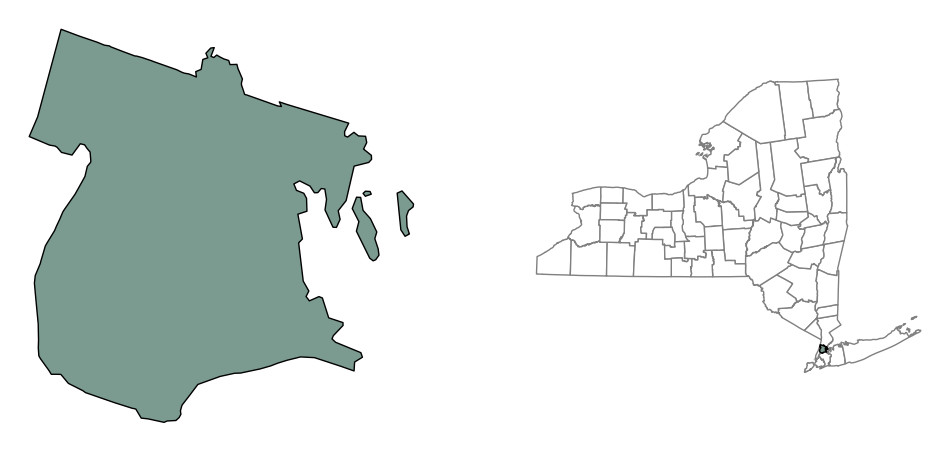

In [86]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
)
county_map("Bronx", axes[0])
locator_map("Bronx", axes[1])

In [109]:
ny_sorted = ny_counties.sort_values('NAME').reset_index(drop=True)

with PdfPages('NY_Counties.pdf') as pdf:
    for county in ny_counties['NAME']:
        county_figure(county, pdf)